# Pump It Up: Data Mining the Water Table

AI7101 — Machine Learning with Python

Majid Alredha · Hamad Alhosani · Hamdan Alhammadi

Predict the operating condition of Tanzanian waterpoints: functional, functional but needing repair, or non-functional. Local water authorities could use these predictions to prioritize inspections and maintenance when they cannot inspect every site.

The practical objective is to find waterpoints needing attention while reducing unnecessary inspections. We compare eight classifiers and assess both overall prediction quality and detection of the less common repair class. Predictions support field decisions; they do not establish water safety or demonstrate that maintenance has improved access to water.

## 1. Setup

The workflow is: reserve a holdout, explore the development data, prepare features, compare models using cross-validation, and evaluate the selected model.

The quick comparison uses 9,000 development records and three folds. The full comparison uses all 47,520 development records and five folds. Every model uses identical rows and folds. A fixed random seed makes the comparison reproducible.

In [2]:
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost

from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    make_scorer,
    classification_report,
    confusion_matrix,
)

from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    BaggingClassifier,
)

from xgboost import XGBClassifier

SEED = 42

# The quick comparison uses a stratified 9,000-row sample.
QUICK_RUN = False
N_SPLITS = 3 if QUICK_RUN else 5

PRIMARY_METRIC = "accuracy"

RUN_FINAL_EVALUATION = True

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "data" / "raw").is_dir():
    REPO_ROOT = REPO_ROOT.parent
DATA_DIR = REPO_ROOT / "data" / "raw"
if not DATA_DIR.is_dir():
    raise FileNotFoundError("Run from the repository root or notebooks/.")
OUTPUT_DIR = REPO_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

CLASS_NAMES = ["functional", "functional needs repair", "non functional"]

# Numeric labels are required by XGBoost.
# All models will use the same encoding.
label_to_number = {name: number for number, name in enumerate(CLASS_NAMES)}
number_to_label = {number: name for name, number in label_to_number.items()}

sns.set_theme(style="whitegrid")
sklearn.set_config(working_memory=128)

print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("Quick run:", QUICK_RUN)
print("CV folds:", N_SPLITS)


scikit-learn: 1.9.1
XGBoost: 3.4.1
Quick run: False
CV folds: 5


## 2. Load and align the data

The supplied data contain 59,400 labeled waterpoints, 39 predictor fields, and 14,850 unlabeled competition records. Features describe location, infrastructure, water availability, funding, and management. Labels are joined by the unique waterpoint `id`.

`X` contains the predictors; `y` contains operating status. The identifier is excluded because it identifies a record rather than describing a waterpoint. The three classes are retained because working pumps requiring repair and failed pumps imply different maintenance actions. Integer encoding changes only their representation. The competition records are used only for final predictions.

Dataset documentation: [DrivenData, Pump It Up](https://www.drivendata.org/competitions/7/pump-it-up-data-mining-the-water-table/page/25/).

In [3]:
# Merge using ID so every pump receives the correct label.

train_values = pd.read_csv(DATA_DIR / "train_values.csv")
train_labels = pd.read_csv(DATA_DIR / "train_labels.csv")
test_values = pd.read_csv(DATA_DIR / "test_values.csv")
submission_format = pd.read_csv(DATA_DIR / "submission_format.csv")

# Check the IDs before joining or making predictions.
for frame in [train_values, train_labels, test_values, submission_format]:
    assert frame["id"].is_unique

assert set(train_values["id"]) == set(train_labels["id"])
assert set(test_values["id"]) == set(submission_format["id"])
assert set(train_values["id"]).isdisjoint(test_values["id"])
assert set(train_values.columns) == set(test_values.columns)

df = train_values.merge(train_labels, on="id", how="left", validate="one_to_one")

assert df["status_group"].notna().all()
assert set(df["status_group"]) == set(CLASS_NAMES)

# Remove the target and identifier from the model inputs.
X = df.drop(columns=["id", "status_group"])

# Encoding changes the label representation, not the classification task.
# 0 = functional, 1 = needs repair, 2 = non functional.
y = df["status_group"].map(label_to_number).astype(int)

X_test = test_values.drop(columns="id")

print("Training inputs:", X.shape)
print("Training target:", y.shape)
print("Competition test inputs:", X_test.shape)

display(df.head())


Training inputs: (59400, 39)
Training target: (59400,)
Competition test inputs: (14850, 39)


,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,...,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group,status_group
0,69572,6000.0,2011-03-14,Roman,1390,Roman,34.938093,-9.856322,none,0,...,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe,functional
1,8776,0.0,2013-03-06,Grumeti,1399,GRUMETI,34.698766,-2.147466,Zahanati,0,...,soft,good,insufficient,insufficient,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional
2,34310,25.0,2013-02-25,Lottery Club,686,World vision,37.460664,-3.821329,Kwa Mahundi,0,...,soft,good,enough,enough,dam,dam,surface,communal standpipe multiple,communal standpipe,functional
3,67743,0.0,2013-01-28,Unicef,263,UNICEF,38.486161,-11.155298,Zahanati Ya Nanyumbu,0,...,soft,good,dry,dry,machine dbh,borehole,groundwater,communal standpipe multiple,communal standpipe,non functional
4,19728,0.0,2011-07-13,Action In A,0,Artisan,31.130847,-1.825359,Shuleni,0,...,soft,good,seasonal,seasonal,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional


## 3. Reserve a holdout set

A stratified 80/20 split reserves 11,880 labeled records for final evaluation and leaves 47,520 for development. Stratification preserves the minority repair class in both sets.

Exploration and hyperparameter selection use only development records. The holdout estimates performance after selecting a model; it must not guide repeated tuning. Random splits assess prediction among similar sampled locations, rather than performance in an entirely new region.

In [4]:
# Stratification preserves class proportions in both sets.
# Use development data for all feature and model decisions.

X_dev, X_holdout, y_dev, y_holdout = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

eda = X_dev.copy()
eda["status_group"] = y_dev.map(number_to_label)

print("Development rows:", len(X_dev))
print("Holdout rows:", len(X_holdout))

class_summary = eda["status_group"].value_counts().to_frame("count")
class_summary["percent"] = 100 * class_summary["count"] / len(eda)

display(class_summary)


Development rows: 47520
Holdout rows: 11880


,count,percent
status_group,,
functional,25807,54.307660
non functional,18259,38.423822
functional needs repair,3454,7.268519


## 4. Explore the development data

The development set is imbalanced: approximately 54.3% of pumps are functional, 38.4% are non-functional, and 7.3% need repair. A majority-class classifier therefore provides a meaningful baseline, while macro-F1 and repair recall reveal errors hidden by overall accuracy.

Missing values are concentrated in management and organization fields; `scheme_name` is missing in about 48.5% of development records. Waterpoint and village names have many unique values, motivating a compact feature set and grouping rare categories.

Literal missing-value counts do not reveal every incomplete measurement. About 34.8% of development records have construction year zero, and about 3.0% have longitude zero. These motivate explicit validity rules before numerical imputation.

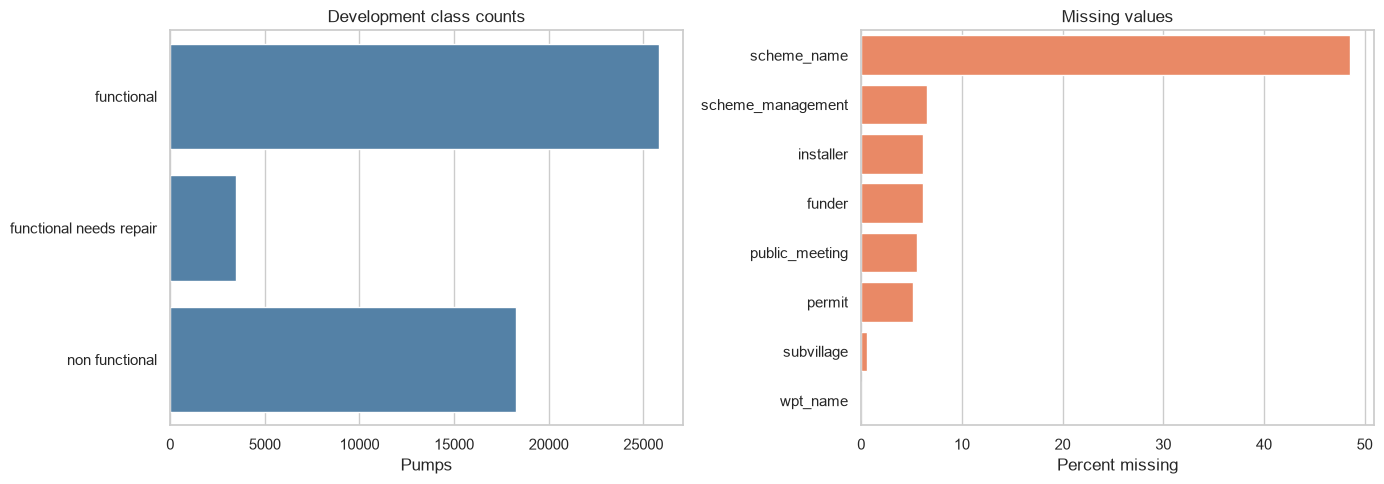

In [ ]:
# Imbalance motivates stratified CV and reporting macro-F1.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=eda, y="status_group", order=CLASS_NAMES, color="steelblue", ax=axes[0]
)
axes[0].set(title="Development class counts", xlabel="Pumps", ylabel="")

missing = X_dev.isna().mean().mul(100).sort_values(ascending=False)
missing = missing[missing > 0]

sns.barplot(x=missing.values, y=missing.index, color="coral", seed=SEED, ax=axes[1])
axes[1].set(title="Missing values", xlabel="Percent missing", ylabel="")

plt.tight_layout()
plt.show()


In [6]:
display(
    pd.DataFrame(
        {"unique_values": X_dev.nunique(), "missing_percent": X_dev.isna().mean() * 100}
    )
)


,unique_values,missing_percent
amount_tsh,94,0.000000
date_recorded,349,0.000000
funder,1715,6.115320
gps_height,2401,0.000000
installer,1929,6.138468
longitude,46029,0.000000
latitude,46027,0.000000
wpt_name,30660,0.004209
num_private,59,0.000000
basin,9,0.000000


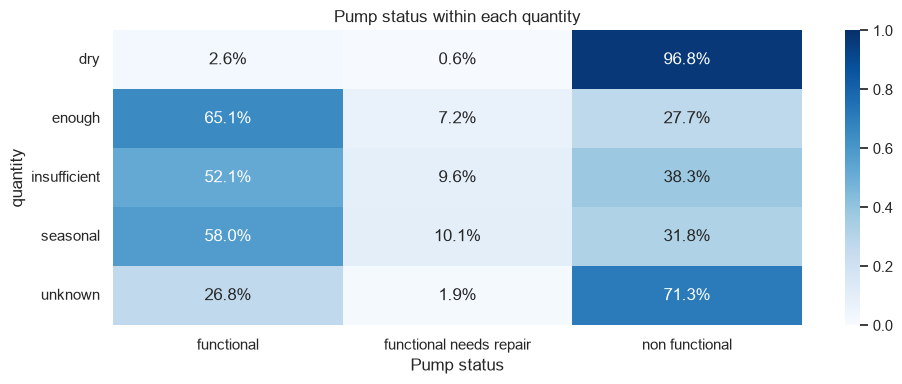

In [ ]:
# Row percentages make differently sized categories easier to compare.
# Always check category counts before interpreting extreme percentages.


def plot_status_by_category(feature):
    proportions = pd.crosstab(
        eda[feature], eda["status_group"], normalize="index"
    ).reindex(columns=CLASS_NAMES, fill_value=0)

    plt.figure(figsize=(10, 4))

    sns.heatmap(proportions, annot=True, fmt=".1%", cmap="Blues", vmin=0, vmax=1)

    plt.title(f"Pump status within each {feature}")
    plt.xlabel("Pump status")
    plt.tight_layout()
    plt.show()


plot_status_by_category("quantity")


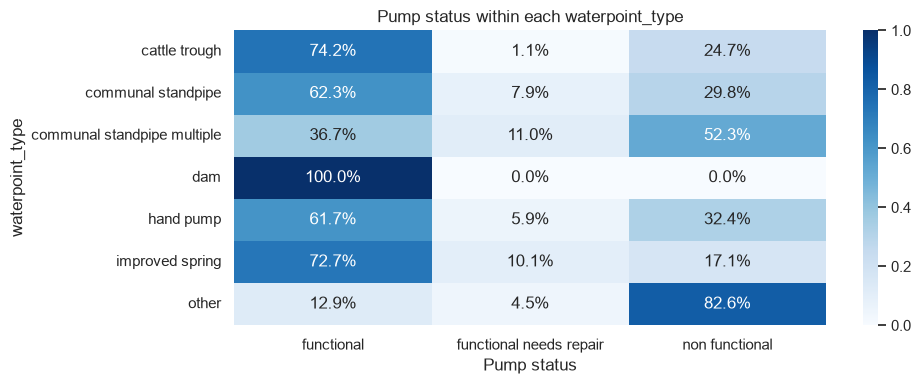

In [8]:
plot_status_by_category("waterpoint_type")


In [9]:
for feature in ["quantity", "waterpoint_type"]:
    display(eda[feature].value_counts().to_frame("pumps"))


,pumps
quantity,
enough,26567
insufficient,12153
dry,4921
seasonal,3244
unknown,635


,pumps
waterpoint_type,
communal standpipe,22778
hand pump,14015
other,5138
communal standpipe multiple,4864
improved spring,631
cattle trough,89
dam,5


### What the exploratory analysis suggests

Water quantity has a strong association with status: about 96.8% of dry waterpoints in the development data are non-functional. Waterpoint type also separates groups: about 82.6% of the `other` category is non-functional. These associations motivate retaining both variables and comparing nonlinear tree models with linear and distance-based alternatives. They are associations, not causal effects.

Small groups require caution: there are only five development records labeled `dam`, so their observed class distribution is weak evidence for generalization. Geographic clustering motivates retaining location information while acknowledging possible optimism from random splits.



## 5. Prepare features

Row-wise transformations apply to every split. Statistics for imputation, scaling, and encoding are learned separately within each training fold, preventing validation information from entering preprocessing.

### Feature engineering decisions

| Transformation | Motivation |
|---|---|
| Remove `recorded_by` and `quantity_group` | A constant contributes no discrimination; the duplicate repeats `quantity`. |
| Exclude waterpoint/village/scheme names and ward | Many categories have little support; scheme names also have extensive missingness. Coordinates, region, LGA, and district preserve location context. This compact choice can discard useful local information. |
| Retain the detailed extraction, management, payment, quality, source, and waterpoint fields | Their related grouped fields repeat or coarsen the same descriptions; excluding those reduces redundant inputs without claiming that every pair is identical. |
| Correct construction year; derive age and recording year | Year zero and construction after recording are inconsistent. Age can reflect wear, while recording year captures collection-period differences. |
| Encode month with sine and cosine | Seasonal patterns may matter; cyclic encoding keeps December and January close. |
| Mark zero/missing coordinate pairs as missing | These pairs do not locate a Tanzanian waterpoint reliably; a flag preserves information about missing location data. |
| Add zero indicators and log-transform population/static head | Zero can be meaningful or a missing-value convention, so it is retained and flagged. Logs reduce the influence of highly skewed values on scaled models. |
| Combine region/district codes as a category; normalize text | District numbers repeat across regions and do not represent distances. Standardizing case and whitespace reduces artificial categorical differences. |

In [10]:
# These rules use individual rows, not statistics learned from other rows.
# Imputation and encoding will be learned inside each CV fold.

DROP_COLUMNS = [
    "recorded_by",  # Constant in these data.
    "wpt_name",  # Many nearly unique names.
    "subvillage",  # High cardinality; excluded in the initial model.
    "scheme_name",  # High cardinality and substantial missingness.
    "ward",  # High cardinality; coordinates and district retain location context.
    "quantity_group",  # Duplicate of quantity.
    "extraction_type_group",
    "extraction_type_class",
    "management_group",
    "payment_type",
    "quality_group",
    "source_type",
    "source_class",
    "waterpoint_type_group",
]

# Check that these columns are redundant in the development data.
assert X_dev["recorded_by"].nunique(dropna=False) == 1
assert X_dev["quantity"].equals(X_dev["quantity_group"])


def engineer_features(frame):
    data = frame.copy()

    # Year 0 is invalid; construction after observation is inconsistent.
    recorded = pd.to_datetime(data["date_recorded"], errors="coerce")
    year = pd.to_numeric(data["construction_year"], errors="coerce")
    year = year.mask((year <= 0) | (year > recorded.dt.year))

    data["construction_year"] = year
    data["pump_age"] = recorded.dt.year - year
    data["record_year"] = recorded.dt.year

    # Cyclic month features place December near January.
    month = recorded.dt.month
    data["month_sin"] = np.sin(2 * np.pi * (month - 1) / 12)
    data["month_cos"] = np.cos(2 * np.pi * (month - 1) / 12)

    # Flag implausible or missing coordinate pairs.
    bad_coordinates = (
        data["longitude"].eq(0)
        | np.isclose(data["latitude"], 0, atol=1e-6)
        | data[["longitude", "latitude"]].isna().any(axis=1)
    )

    data["coordinates_missing"] = bad_coordinates.astype(int)
    data.loc[bad_coordinates, ["longitude", "latitude"]] = np.nan

    # Preserve ambiguous zeros and give models explicit zero indicators.
    for column in ["population", "gps_height", "amount_tsh"]:
        data[column + "_is_zero"] = data[column].eq(0).astype(int)

    # Compress skewed nonnegative measurements for KNN and logistic regression.
    for column in ["population", "amount_tsh"]:
        data[column + "_log1p"] = np.log1p(data[column].clip(lower=0))

    # Administrative codes are category labels, not numeric distances.
    data["district_id"] = (
        data["region_code"].astype(str) + "_" + data["district_code"].astype(str)
    )

    data = data.drop(
        columns=DROP_COLUMNS
        + ["date_recorded", "region_code", "district_code", "population", "amount_tsh"]
    )

    # Standardize text while preserving genuinely missing values.
    categorical = data.select_dtypes(include=["object", "string", "bool"]).columns

    for column in categorical:
        data[column] = data[column].map(
            lambda value: str(value).strip().lower() if pd.notna(value) else np.nan
        )
        data[column] = data[column].replace("", np.nan)

    return data


X_dev_clean = engineer_features(X_dev)
X_holdout_clean = engineer_features(X_holdout)
X_test_clean = engineer_features(X_test)

display(X_dev_clean.head())
print("Prepared development shape:", X_dev_clean.shape)


,funder,gps_height,installer,longitude,latitude,num_private,basin,region,lga,public_meeting,...,record_year,month_sin,month_cos,coordinates_missing,population_is_zero,gps_height_is_zero,amount_tsh_is_zero,population_log1p,amount_tsh_log1p,district_id
43360,NaN,0,NaN,33.542898,-9.174777,0,lake nyasa,mbeya,rungwe,true,...,2011,1.224647e-16,-1.0,0,1,1,1,0.000000,0.000000,12_4
7263,rc church,2049,acra,34.665760,-9.308548,0,rufiji,iringa,njombe,true,...,2011,8.660254e-01,0.5,0,0,0,0,5.170484,6.216606,11_4
2486,donor,290,do,38.238568,-6.179919,0,wami / ruvu,pwani,bagamoyo,true,...,2011,8.660254e-01,0.5,0,0,0,0,7.741099,3.258097,6_1
313,government of tanzania,0,dwe,30.716727,-1.289055,0,lake victoria,kagera,karagwe,true,...,2011,1.224647e-16,-1.0,0,1,1,1,0.000000,0.000000,18_1
52726,water,0,gove,35.389331,-6.399942,0,internal,dodoma,bahi,true,...,2011,8.660254e-01,0.5,0,1,1,1,0.000000,0.000000,1_6


Prepared development shape: (47520, 31)


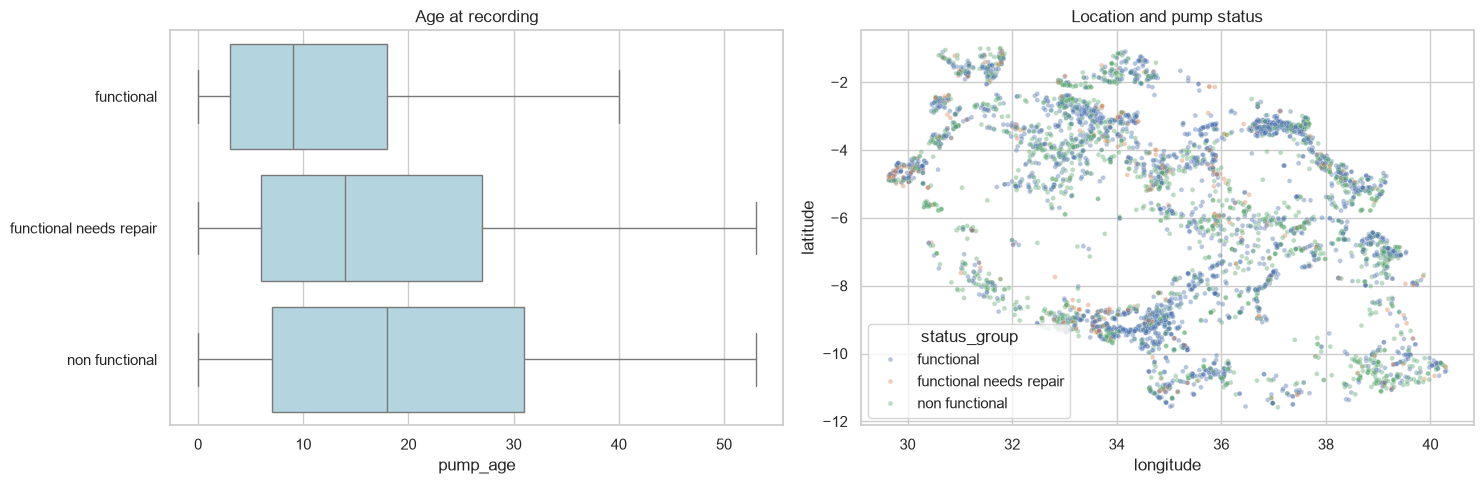

In [11]:
# Spatial clustering can limit generalization to unseen regions.

plot_data = X_dev_clean.copy()
plot_data["status_group"] = y_dev.map(number_to_label)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(
    data=plot_data,
    x="pump_age",
    y="status_group",
    order=CLASS_NAMES,
    showfliers=False,
    color="lightblue",
    ax=axes[0],
)
axes[0].set(title="Age at recording", ylabel="")

sample = plot_data.sample(n=min(5000, len(plot_data)), random_state=SEED)

sns.scatterplot(
    data=sample,
    x="longitude",
    y="latitude",
    hue="status_group",
    hue_order=CLASS_NAMES,
    alpha=0.4,
    s=12,
    ax=axes[1],
)
axes[1].set_title("Location and pump status")

plt.tight_layout()
plt.show()


## 6. Compare models with cross-validation

Accuracy measures the fraction of waterpoints assigned the correct operating condition and is the declared selection criterion. Macro-F1 gives each class equal weight, highlighting minority-class errors; repair recall measures the fraction of actual repair cases detected. Accuracy alone is insufficient for a maintenance decision.

Shuffled stratified cross-validation keeps the rare repair class represented in each fold. All models use the same folds, providing a controlled comparison. Grid search selects hyperparameters on development data; the separate holdout evaluates the selected configuration. Fold standard deviations describe variation across folds, rather than confidence intervals.

### Preprocessing inside each fold

Numeric features use median imputation to limit the influence of extreme values. Missingness indicators allow models to use the fact that a measurement was absent. Categorical missing values receive an explicit category rather than being replaced with the most common response.

One-hot encoding avoids imposing an order on nominal categories. Categories appearing fewer than 20 times in a training fold are grouped, with at most 50 encoded categories per field; this controls feature count and reduces reliance on very small groups. The trade-off is lost detail in rare locations and organizations. Unseen categories are handled without failing at prediction time.

Numeric standardization is applied to KNN and logistic regression because their distances or coefficients depend on scale. Tree models do not require that scaling. All fitted transformations belong to the model pipeline and are learned only from the training portion of each fold.

In [12]:
# All learned preprocessing is fitted inside the training fold.
# Numeric scaling is used only for KNN and multinomial logistic regression.

numeric_columns = X_dev_clean.select_dtypes(include="number").columns.tolist()
categorical_columns = X_dev_clean.columns.difference(numeric_columns).tolist()


def make_pipeline(model, scale_numeric=False):
    numeric_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]

    if scale_numeric:
        numeric_steps.append(("scale", StandardScaler()))

    categorical_steps = Pipeline(
        [
            ("impute", SimpleImputer(strategy="constant", fill_value="__missing__")),
            (
                "encode",
                OneHotEncoder(
                    handle_unknown="infrequent_if_exist",
                    min_frequency=20,
                    max_categories=50,
                    sparse_output=True,
                ),
            ),
        ]
    )

    preprocess = ColumnTransformer(
        [
            ("numeric", Pipeline(numeric_steps), numeric_columns),
            ("categorical", categorical_steps, categorical_columns),
        ],
        sparse_threshold=1.0,
    )

    return Pipeline([("preprocess", preprocess), ("model", model)])


In [13]:
# Every model receives the same rows and folds for a fair comparison.
# Repair recall measures how many actual repair cases are detected.

if QUICK_RUN:
    X_fit, _, y_fit, _ = train_test_split(
        X_dev_clean, y_dev, train_size=9000, stratify=y_dev, random_state=SEED
    )
else:
    X_fit = X_dev_clean
    y_fit = y_dev

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

folds = list(cv.split(X_fit, y_fit))

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "repair_recall": make_scorer(
        recall_score,
        labels=[1],  # Class 1 means functional needs repair.
        average="macro",
        zero_division=0,
    ),
}

assert PRIMARY_METRIC in scoring

print("Rows used by every model:", len(X_fit))
print("CV folds:", len(folds))
print("Selection metric:", PRIMARY_METRIC)


Rows used by every model: 47520
CV folds: 5
Selection metric: accuracy


### Why these models and searches?

| Model | Purpose and tuning choices |
|---|---|
| Majority baseline | Establish the performance achieved without learning feature relationships. |
| KNN | Test local similarity; neighbor count and distance weighting control smoothing. Sparse one-hot distances may be weak in many dimensions. |
| Multinomial logistic regression | Provide a regularized linear reference; tune regularization and balanced class weights. |
| Decision tree | Capture interpretable nonlinear splits; depth and leaf size control overfitting. |
| Random forest | Average bootstrap trees; feature sampling and leaf size control diversity and complexity. |
| Extra Trees | Test more randomized splits using the same feature-sampling and leaf-size choices. |
| Bagging trees | Contrast bootstrap averaging with forests' additional feature sampling; tune sample fraction and leaf size. |
| XGBoost | Fit sequential trees that correct earlier errors; tune depth, learning rate, and 250 versus 500 boosting rounds. |

These small grids compare plausible alternatives at manageable cost; they do not exhaust each algorithm's possibilities. A higher repair recall may come at the expense of overall accuracy, so the three reported metrics must be interpreted together.

In [ ]:
# Bagging trains decision trees on bootstrap samples.
# Random forest also randomizes feature selection at individual splits.
# XGBoost builds boosted trees for the three-class task.

experiments = {
    "Majority baseline": (
        make_pipeline(DummyClassifier(strategy="most_frequent", random_state=SEED)),
        {},
    ),
    "KNN": (
        make_pipeline(
            KNeighborsClassifier(algorithm="brute", n_jobs=2), scale_numeric=True
        ),
        {"model__n_neighbors": [11, 31], "model__weights": ["uniform", "distance"]},
    ),
    "Multinomial logistic regression": (
        make_pipeline(
            # lbfgs optimizes multinomial loss for the three-class task.
            LogisticRegression(solver="lbfgs", max_iter=3000, random_state=SEED),
            scale_numeric=True,
        ),
        {"model__C": [0.1, 1.0], "model__class_weight": [None, "balanced"]},
    ),
    "Decision tree": (
        make_pipeline(DecisionTreeClassifier(random_state=SEED)),
        {"model__max_depth": [10, 20, None], "model__min_samples_leaf": [2, 10]},
    ),
    "Random forest": (
        make_pipeline(
            RandomForestClassifier(n_estimators=150, random_state=SEED, n_jobs=2)
        ),
        {"model__max_features": ["sqrt", 0.5], "model__min_samples_leaf": [1, 5]},
    ),
    "Extra Trees": (
        make_pipeline(
            ExtraTreesClassifier(n_estimators=150, random_state=SEED, n_jobs=2)
        ),
        {"model__max_features": ["sqrt", 0.5], "model__min_samples_leaf": [1, 5]},
    ),
    "Bagging trees": (
        make_pipeline(
            BaggingClassifier(
                estimator=DecisionTreeClassifier(random_state=SEED),
                n_estimators=100,
                bootstrap=True,
                random_state=SEED,
                n_jobs=2,
            )
        ),
        {
            "model__max_samples": [0.7, 1.0],
            "model__estimator__min_samples_leaf": [2, 5],
        },
    ),
    "XGBoost": (
        make_pipeline(
            XGBClassifier(
                objective="multi:softprob",
                num_class=3,
                eval_metric="mlogloss",
                tree_method="hist",
                n_estimators=250,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=SEED,
                n_jobs=2,
            )
        ),
        {
            "model__max_depth": [4, 7],
            "model__learning_rate": [0.05, 0.1],
            "model__n_estimators": [250, 500],
        },
    ),
}

print("Models:", list(experiments))


Models: ['Majority baseline', 'KNN', 'Multinomial logistic regression', 'Decision tree', 'Random forest', 'Extra Trees', 'Bagging trees', 'XGBoost']


In [ ]:
searches = {}
rows = []

for name, (pipeline, parameters) in experiments.items():
    print(f"\nStarting: {name}", flush=True)
    start = perf_counter()

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=parameters,
        scoring=scoring,
        refit=PRIMARY_METRIC,
        cv=folds,
        n_jobs=1,
        return_train_score=False,
        error_score="raise",
        verbose=1,
    )

    search.fit(X_fit, y_fit)
    searches[name] = search

    best = search.best_index_
    scores = search.cv_results_

    row = {
        "model": name,
        "search_seconds": perf_counter() - start,
        "best_parameters": search.best_params_,
    }

    for metric in scoring:
        row["cv_" + metric] = scores["mean_test_" + metric][best]
        row["sd_" + metric] = scores["std_test_" + metric][best]

    rows.append(row)

    filename = name.lower().replace(" ", "_") + "_search.csv"
    pd.DataFrame(scores).to_csv(OUTPUT_DIR / filename, index=False)

    print("Best parameters:", search.best_params_, flush=True)

# Select by the declared primary metric, with a secondary tie-breaker.
primary_column = "cv_" + PRIMARY_METRIC
secondary_column = "cv_macro_f1" if PRIMARY_METRIC != "macro_f1" else "cv_accuracy"

results = (
    pd.DataFrame(rows)
    .sort_values([primary_column, secondary_column], ascending=False)
    .reset_index(drop=True)
)

results.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)

# CV selection scores may be optimistic after searching many configurations.
winner_name = results.loc[0, "model"]
winner = searches[winner_name].best_estimator_

print("Selected model:", winner_name)



Starting: Majority baseline
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Best parameters: {}

Starting: KNN
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'model__n_neighbors': 11, 'model__weights': 'distance'}

Starting: Multinomial logistic regression
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'model__C': 1.0, 'model__class_weight': None}

Starting: Decision tree
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best parameters: {'model__max_depth': 20, 'model__min_samples_leaf': 2}

Starting: Random forest
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'model__max_features': 0.5, 'model__min_samples_leaf': 5}

Starting: Extra Trees
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'model__max_features': 0.5, 'model__min_samples_leaf': 5}

Starting: Bagging trees
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameter

### Cross-validation results

In [ ]:
display(
    results[["model", "cv_accuracy", "cv_macro_f1", "cv_repair_recall", "sd_accuracy"]]
    .rename(
        columns={
            "model": "Model",
            "cv_accuracy": "Accuracy",
            "cv_macro_f1": "Macro-F1",
            "cv_repair_recall": "Repair recall",
            "sd_accuracy": "Accuracy SD",
        }
    )
    .round(4)
)


,Model,Accuracy,Macro-F1,Repair recall,Accuracy SD
0,XGBoost,0.8059,0.6866,0.3121,0.0029
1,Random forest,0.8059,0.6792,0.2808,0.0048
2,Bagging trees,0.8044,0.6854,0.3141,0.0056
3,Extra Trees,0.7996,0.6763,0.2939,0.0025
4,KNN,0.7793,0.6667,0.3385,0.0045
5,Decision tree,0.7670,0.6379,0.2777,0.0024
6,Multinomial logistic regression,0.7539,0.5912,0.1491,0.0013
7,Majority baseline,0.5431,0.2346,0.0000,0.0001


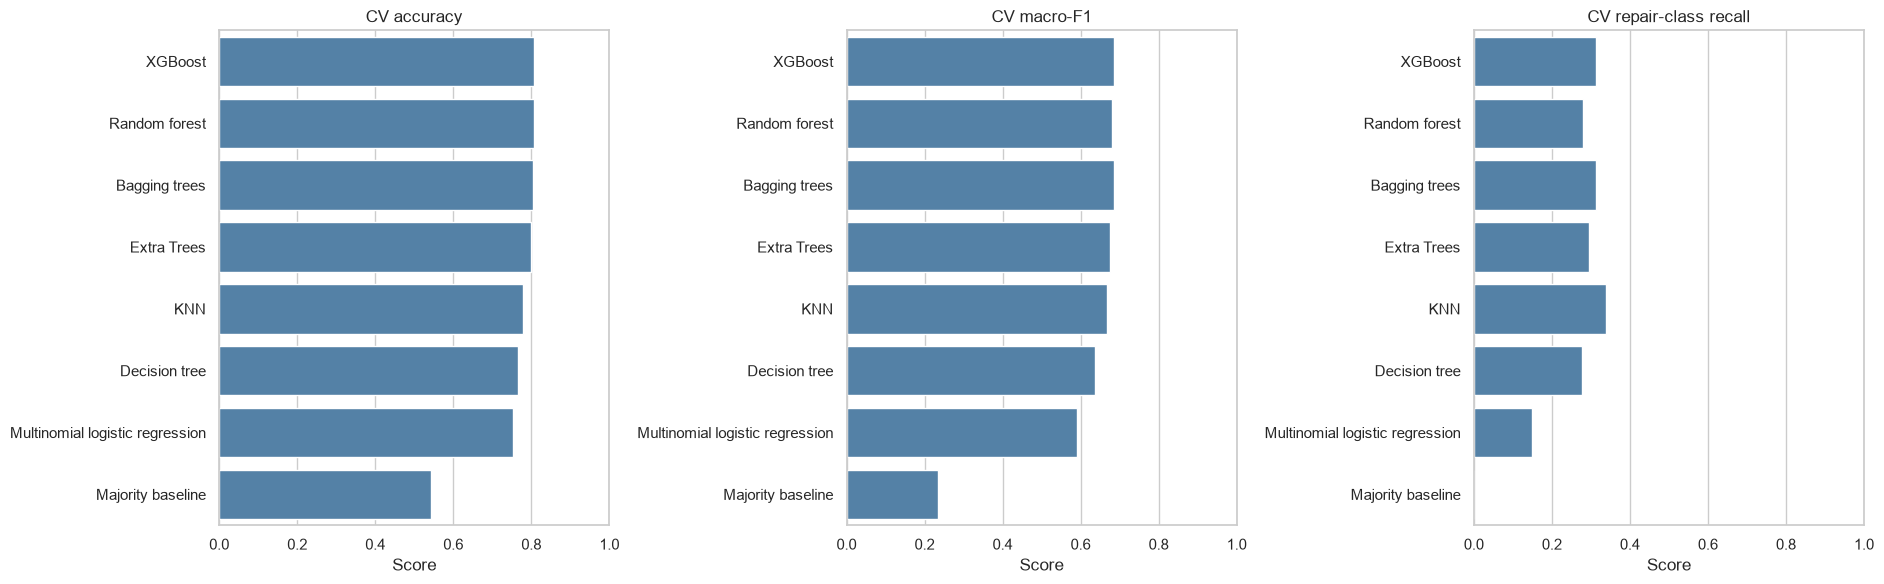

In [ ]:
# Accuracy, macro-F1, and repair recall answer different questions.
# Fold standard deviations are variability measures, not confidence intervals.

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

metrics = [
    ("cv_accuracy", "CV accuracy"),
    ("cv_macro_f1", "CV macro-F1"),
    ("cv_repair_recall", "CV repair-class recall"),
]

for ax, (metric, title) in zip(axes, metrics):
    sns.barplot(
        data=results,
        x=metric,
        y="model",
        order=results["model"].tolist(),
        color="steelblue",
        seed=SEED,
        ax=ax,
    )

    ax.set(title=title, xlabel="Score", ylabel="", xlim=(0, 1))

plt.tight_layout()
plt.show()


### Model comparison: full development set

**XGBoost** leads on the declared selection metric: mean CV accuracy 80.59%, with fold SD 0.29%. The majority baseline scores 54.31%; the gain is 26.28 percentage points.

The selected model's macro-F1 is 0.687 and repair recall is 31.21%. The highest repair recall belongs to KNN (33.85%), showing that the accuracy winner need not be the strongest repair detector.

Logistic regression reaches 75.39% accuracy and KNN reaches 77.93%. The table and plots compare these references with nonlinear tree ensembles. Small score gaps relative to fold variation do not establish a reliable ordering. Searching configurations on the same folds also makes the selected CV score optimistic.

Selected parameters: `{'model__learning_rate': 0.1, 'model__max_depth': 7, 'model__n_estimators': 500}`. Comparison uses 47,520 development records and 5 folds.

## 7. Final holdout evaluation

The selected configuration is evaluated on the untouched holdout alongside the majority baseline. Accuracy and macro-F1 summarize performance; the classification report and count/normalized confusion matrices identify class-specific errors.

Confusing a failed pump with a functional pump can leave a site unattended. Confusing a functional pump with one needing attention creates an unnecessary inspection. The repair class deserves separate scrutiny because it is rare and can be confused with either neighboring operating condition.

,model,holdout_accuracy,holdout_macro_f1
0,XGBoost,0.807155,0.678940
1,Majority baseline,0.543098,0.234635


                         precision    recall  f1-score   support

             functional       0.80      0.91      0.85      6452
functional needs repair       0.60      0.28      0.38       863
         non functional       0.85      0.77      0.81      4565

               accuracy                           0.81     11880
              macro avg       0.75      0.65      0.68     11880
           weighted avg       0.80      0.81      0.80     11880



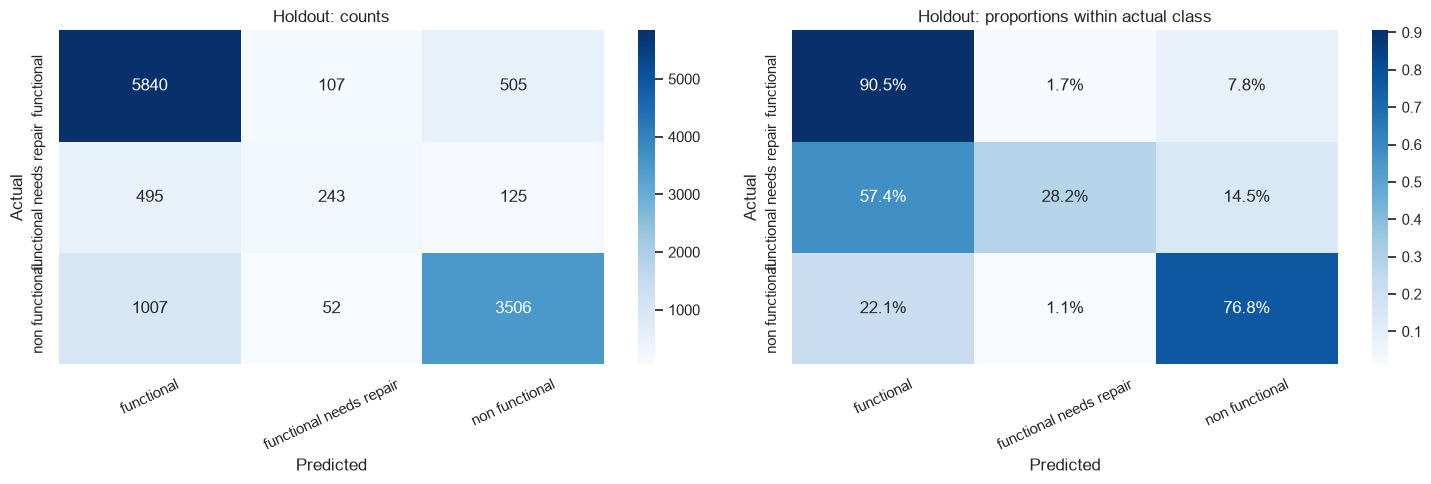

In [19]:
# Holdout results are reported only after model selection.


def predict_in_batches(model, frame, batch_size=500):
    predictions = []

    for start in range(0, len(frame), batch_size):
        batch = frame.iloc[start : start + batch_size]
        predictions.append(model.predict(batch))

    return np.concatenate(predictions).astype(int)


holdout_evaluated = False

if QUICK_RUN or not RUN_FINAL_EVALUATION:
    print("Holdout evaluation is not included in this run.")
else:
    if not X_fit.index.equals(X_dev_clean.index) or not y_fit.index.equals(y_dev.index):
        raise RuntimeError("Rerun model selection on the full development set.")

    holdout_pred = predict_in_batches(winner, X_holdout_clean)

    comparisons = [(winner_name, holdout_pred)]
    if winner_name != "Majority baseline":
        baseline = searches["Majority baseline"].best_estimator_
        baseline_pred = predict_in_batches(baseline, X_holdout_clean)
        comparisons.append(("Majority baseline", baseline_pred))

    final_rows = []

    for name, prediction in comparisons:
        final_rows.append(
            {
                "model": name,
                "holdout_accuracy": accuracy_score(y_holdout, prediction),
                "holdout_macro_f1": f1_score(y_holdout, prediction, average="macro"),
            }
        )

    final_scores = pd.DataFrame(final_rows)
    display(final_scores)
    final_scores.to_csv(OUTPUT_DIR / "holdout_scores.csv", index=False)

    print(
        classification_report(
            y_holdout,
            holdout_pred,
            labels=[0, 1, 2],
            target_names=CLASS_NAMES,
            zero_division=0,
        )
    )

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    for ax, normalization, title, number_format in [
        (axes[0], None, "Holdout: counts", "d"),
        (axes[1], "true", "Holdout: proportions within actual class", ".1%"),
    ]:
        matrix = confusion_matrix(
            y_holdout, holdout_pred, labels=[0, 1, 2], normalize=normalization
        )

        sns.heatmap(
            matrix,
            annot=True,
            fmt=number_format,
            cmap="Blues",
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES,
            ax=ax,
        )

        ax.set(title=title, xlabel="Predicted", ylabel="Actual")
        ax.tick_params(axis="x", rotation=25)

    plt.tight_layout()
    plt.show()

    holdout_evaluated = True


## 8. Inspection-policy scenario

An illustrative policy flags predicted repair and non-functional cases for inspection. Inspection yield is the fraction of flagged pumps actually needing attention; coverage is the fraction of all attention cases found. These measures translate classification errors into a field decision.

The scenario assigns 20 arbitrary units per inspection and 100 per missed attention case. It compares targeted inspections with inspecting every pump, and reports the attention prevalence as the expected yield of random inspections. The assumptions are illustrative: they exclude travel, repair costs, capacity constraints, and field outcomes. They cannot establish realized financial savings.

In [20]:
# Flag pumps predicted as needing repair or being non-functional.
# This policy does not change the original three-class model.
# The cost values below are hypothetical, not measured savings.

if not holdout_evaluated:
    print("Inspection-policy results require the final holdout predictions.")
else:
    actual_attention = y_holdout.to_numpy() != 0
    flagged = holdout_pred != 0

    true_positive = np.sum(flagged & actual_attention)
    false_positive = np.sum(flagged & ~actual_attention)
    false_negative = np.sum(~flagged & actual_attention)

    inspection_yield = true_positive / max(flagged.sum(), 1)
    coverage = true_positive / max(actual_attention.sum(), 1)

    display(
        pd.Series(
            {
                "pumps_flagged": int(flagged.sum()),
                "attention_cases_found": int(true_positive),
                "functional_pumps_flagged": int(false_positive),
                "attention_cases_missed": int(false_negative),
                "inspection_yield": inspection_yield,
                "coverage": coverage,
                "random_inspection_expected_yield": actual_attention.mean(),
            }
        )
    )

    # Illustrative cost assumptions, not observed financial outcomes.
    inspection_cost = 20
    missed_case_penalty = 100

    model_cost = flagged.sum() * inspection_cost + false_negative * missed_case_penalty
    inspect_all_cost = len(y_holdout) * inspection_cost

    print("Hypothetical model-policy cost:", model_cost)
    print("Hypothetical inspect-all cost:", inspect_all_cost)
    print("Hypothetical difference:", inspect_all_cost - model_cost)

    # Positive difference favors the model under these assumptions.
    # This scenario excludes repair costs, travel, and actual field outcomes.


pumps_flagged                       4538.000000
attention_cases_found               3926.000000
functional_pumps_flagged             612.000000
attention_cases_missed              1502.000000
inspection_yield                       0.865139
coverage                               0.723287
random_inspection_expected_yield       0.456902
dtype: float64

Hypothetical model-policy cost: 240960
Hypothetical inspect-all cost: 237600
Hypothetical difference: -3360


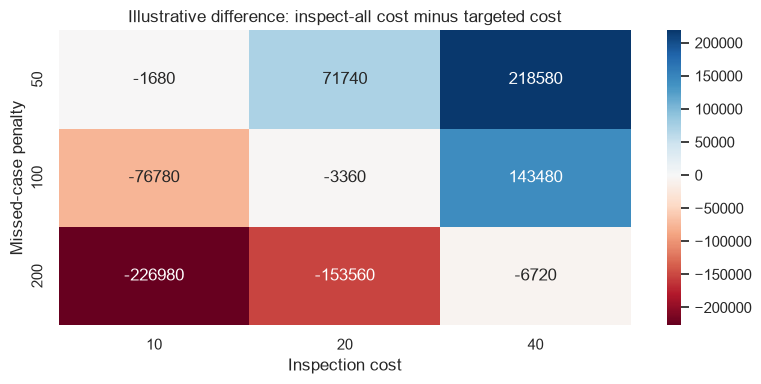

In [ ]:
if holdout_evaluated:
    cost_sensitivity = pd.DataFrame(
        {
            cost: [
                (len(y_holdout) - flagged.sum()) * cost - false_negative * penalty
                for penalty in [50, 100, 200]
            ]
            for cost in [10, 20, 40]
        },
        index=pd.Index([50, 100, 200], name="Missed-case penalty"),
    )
    plt.figure(figsize=(8, 4))
    sns.heatmap(cost_sensitivity, annot=True, fmt=".0f", cmap="RdBu", center=0)
    plt.xlabel("Inspection cost")
    plt.title("Illustrative difference: inspect-all cost minus targeted cost")
    plt.tight_layout()
    plt.show()


### What the inspection scenario implies

The policy flags 4,538 of 11,880 holdout waterpoints, with inspection yield 86.51% and attention-case coverage 72.33%. It misses 1,502 attention cases. Random inspection would have an expected yield of 45.69% under uniform sampling.

Under the illustrative 20/100 cost assumptions, the difference relative to inspecting every site is -3,360 units. Positive values favor targeted inspection under those assumptions. The heatmap varies both costs to show whether that conclusion depends on their chosen values. Real deployment requires locally estimated costs and a prospective field evaluation.

## 9. Refit and write a submission

After recording holdout performance, a fresh copy of the selected configuration is fitted on all 59,400 labeled records. Predictions are converted back to the three original labels and aligned to the competition template by `id`.

The resulting CSV contains 14,850 rows in the required ID order. Competition predictions have no local ground-truth labels and therefore do not provide an additional validation score.

In [22]:
# After recording holdout performance, use all 59,400 labeled pumps.
# Convert numeric predictions back to the exact required class names.

if not holdout_evaluated:
    print("Competition predictions are not generated in this run.")
else:
    final_model = clone(winner)
    final_model.fit(engineer_features(X), y)

    test_predictions = predict_in_batches(final_model, X_test_clean)

    predictions_by_id = pd.Series(test_predictions, index=test_values["id"]).map(
        number_to_label
    )

    # Map by ID rather than assuming the template has the same row order.
    submission = submission_format[["id"]].copy()
    submission["status_group"] = submission["id"].map(predictions_by_id)

    assert submission.columns.tolist() == ["id", "status_group"]
    assert len(submission) == len(test_values)
    assert submission["id"].equals(submission_format["id"])
    assert submission["status_group"].notna().all()
    assert set(submission["status_group"]).issubset(CLASS_NAMES)

    submission_path = OUTPUT_DIR / "submission.csv"
    submission.to_csv(submission_path, index=False)

    display(submission.head())
    print("Saved:", submission_path)


,id,status_group
0,50785,functional
1,51630,functional
2,17168,functional
3,45559,non functional
4,49871,functional


Saved: /Users/mayed/Documents/AI7101/Project/pump-it-up-water-pumps/outputs/submission.csv


## 10. Limitations and practical use

- **Minority-class performance:** overall accuracy can be high while repair cases are missed. An inspection policy needs explicit attention to missed cases and available inspection capacity.
- **Geographic and time shift:** nearby sites and shared infrastructure can make random validation optimistic. These historical records do not establish performance in today's conditions or unseen regions; grouped regional and temporal validation are appropriate next evaluations.
- **Feature availability:** variables such as observed water quantity may require a site visit. Authorities must check which predictors are available before using the model to choose inspection locations.
- **Representation and search:** excluding rare location fields and grouping categories trades detail for stability. The small grids and quick sample limit claims about the best achievable model.
- **Impact:** the model predicts recorded operating condition, not future failures, safe drinking water, or the causal effect of maintenance. Field verification, updated labels, and locally justified costs are needed before deployment.

## 11. Overall conclusion

**XGBoost** was selected using development-set CV and obtains holdout accuracy 80.72%, macro-F1 0.679, and repair recall 28.16%. These holdout scores provide an evaluation separate from the configuration search.

For the illustrative inspection policy, attention-case coverage is 72.33% and inspection yield is 86.51%. The model therefore offers a quantified trade-off between inspection effort and missed cases; it does not remove the need for field verification. Whether that trade-off meets an authority's needs depends on its capacity, costs, and tolerance for missed repairs.

A classification model can support prioritization, provided its predictors are available before inspection and its errors are acceptable in the intended setting. The next steps are validation across regions and collection periods, examination of minority-class errors, and a field pilot comparing inspection yield and missed cases with existing practice.

## References

1. [DrivenData: Pump It Up dataset, target definitions, and submission format](https://www.drivendata.org/competitions/7/pump-it-up-data-mining-the-water-table/page/25/).
2. [scikit-learn: GridSearchCV and selection/refitting behavior](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
3. [scikit-learn: cross-validation and evaluation](https://scikit-learn.org/stable/modules/cross_validation.html).
4. [XGBoost: Python API](https://xgboost.readthedocs.io/en/stable/python/python_api.html).